(shakespeare_char_gpt)=
# Character-level GPT on Shakespeare

This example builds a small GPT by hand from pytensor-ml layers and trains it to predict the next
character of the complete works of Shakespeare, following the character-level Shakespeare model in
nanoGPT {cite:p}`karpathy2022nanogpt`. The architecture follows GPT-2 {cite:p}`radford2019language`: a
stack of causal transformer blocks {cite:p}`vaswani2017attention` between an embedding layer and an
output head.

In [1]:
import pytensor

floatX = "float32"
pytensor.config.floatX = floatX

In [2]:
import urllib.request

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pytensor.tensor as pt
import pytensor.tensor.random as ptr

from tqdm.auto import tqdm

from pytensor_ml.activations import GELU
from pytensor_ml.layers import Embedding, Input, LayerNorm, TransformerBlock
from pytensor_ml.loss import CrossEntropy
from pytensor_ml.model import Model
from pytensor_ml.optim import (
    adamw,
    chain,
    clip_by_global_norm,
    cosine_schedule,
    join_schedules,
    linear_schedule,
)
from pytensor_ml.state import NormalInitializer

## Data

The dataset is tiny Shakespeare from char-rnn {cite:p}`karpathy2015charrnn`, about a million characters
of plays in one text file. Each distinct character is one token, so the vocabulary is the sorted set of
characters in the file. The first 90% of the text is the training set and the remaining 10% the
validation set, kept contiguous as in nanoGPT.

In [3]:
DATA_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)
data_path = Path("../data/input.txt")

if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, data_path)

text = data_path.read_text()
len(text)

1115394

In [4]:
characters = sorted(set(text))
vocab_size = len(characters)
char_to_id = {character: index for index, character in enumerate(characters)}


def encode(string):
    return np.array([char_to_id[character] for character in string], dtype=np.int64)


def decode(ids):
    return "".join(characters[index] for index in ids)


token_ids = encode(text)
n_train = int(0.9 * len(token_ids))
train_ids, val_ids = token_ids[:n_train], token_ids[n_train:]

vocab_size, len(train_ids), len(val_ids)

(65, 1003854, 111540)

A training batch is `batch_size` windows of `block_size` characters, each starting at a random offset.
The target for each window is the same window shifted one character ahead, so every position is trained
to predict the character that follows it.

In [5]:
block_size = 64
batch_size = 12
rng = np.random.default_rng(sum(map(ord, "shakespeare char gpt")))


def get_batch(ids, *, rng, block_size, batch_size):
    starts = rng.integers(len(ids) - block_size, size=batch_size)
    windows = starts[:, None] + np.arange(block_size)
    return ids[windows], ids[windows + 1]


X_batch, y_batch = get_batch(train_ids, rng=rng, block_size=block_size, batch_size=batch_size)
X_batch.shape, decode(X_batch[0, :32]), decode(y_batch[0, :32])

((12, 64),
 'esar build that place, my lord?\n',
 'sar build that place, my lord?\n\n')

## Model

The network follows nanoGPT's CPU configuration: four pre-norm transformer blocks of width 128 with four
causal attention heads each. Token and position embeddings are summed at the input, and the output head
reuses the token embedding matrix, so the logit for each character is the dot product of the final
hidden state with that character's embedding. Calling the layers on the symbolic `tokens` input builds
the graph without computing anything.

The projections carry no bias terms, as in nanoGPT. The layer norms keep their learned shift, which
nanoGPT also drops, so this model has 1,152 more parameters than nanoGPT's 804,096.

In [6]:
n_layer = 4
n_head = 4
n_embd = 128

token_embedding = Embedding("token_embedding", n_embeddings=vocab_size, n_features=n_embd)
position_embedding = Embedding("position_embedding", n_embeddings=block_size, n_features=n_embd)
blocks = [
    TransformerBlock(
        f"block_{index}",
        d_model=n_embd,
        n_head=n_head,
        activation=GELU(approximate=False),
        bias=False,
        is_causal=True,
        fused_qkv=True,
    )
    for index in range(n_layer)
]
final_norm = LayerNorm("final_norm", n_in=n_embd)


def forward(token_ids):
    hidden = token_embedding(token_ids) + position_embedding(pt.arange(token_ids.shape[1]))
    for block in blocks:
        hidden = block(hidden)
    return final_norm(hidden) @ token_embedding.W.T


# PyTensor allows dynamic shapes, but GPU-enabled backends (jax and mlx) want static shapes. So for
# maximum flexibility we define an input shape here.
tokens = Input("tokens", shape=(batch_size, block_size), dtype="int64")
logits = forward(tokens)

nanoGPT draws every weight matrix from a normal distribution with standard deviation 0.02, and shrinks it
by $1/\sqrt{2 n_\text{layer}}$ on the two projections in each block that write into the residual
stream, the attention output and the second feed-forward layer. Each block adds both of them to the
stream, so the scaling keeps the residual variance from growing with depth.
{meth}`~pytensor_ml.model.Model.initialize` takes that scheme as a mapping from parameter to
initializer, and every parameter left out of it keeps its layer's default.

In [7]:
standard = NormalInitializer(std=0.02)
residual = NormalInitializer(std=0.02 / np.sqrt(2 * n_layer))

initializers = {token_embedding.W: standard, position_embedding.W: standard}
for block in blocks:
    initializers |= {
        block.attn.qkv_proj.W: standard,
        block.ff.fc_in.W: standard,
        block.attn.out_proj.W: residual,
        block.ff.fc_out.W: residual,
    }

model = Model(logits).initialize(seed=0, initializers=initializers)
sum(weight.get_value().size for weight in model.weights)

805248

## Training

The optimizer settings are nanoGPT's for this model. AdamW {cite:p}`loshchilov2019adamw` applies weight
decay of 0.1 to the weight matrices and embeddings only, leaving the layer norm parameters undecayed, and
gradients are clipped to a global norm of 1 before each update. The learning rate warms up linearly to
$10^{-3}$ over the first 100 steps, then follows a cosine down to $10^{-4}$ at the last step.

In [8]:
n_steps = 4_000
warmup_steps = 100

learning_rate = join_schedules(
    [
        linear_schedule(0.0, total_steps=warmup_steps, final_learning_rate=1e-3),
        cosine_schedule(1e-3, total_steps=n_steps - warmup_steps, final_learning_rate=1e-4),
    ],
    boundaries=[warmup_steps],
)
rule = chain(
    clip_by_global_norm(max_norm=1.0),
    adamw(
        learning_rate=learning_rate,
        weight_decay=0.1,
        beta2=0.99,
        mask=lambda parameter: parameter.ndim > 1,
    ),
)

loss = CrossEntropy(expect_logits=True)
step_fn = model.compile_train(rule, loss)

Every `eval_interval` steps the loop scores `eval_size` fresh windows from each split. The evaluation
graph applies `forward` and the same loss to inputs of its own fixed shape, and compiles once as its own
function. The model has no dropout or batch norm, so the network it trains is also the network it
predicts with. The per-step training loss comes from a single batch of 12 windows and is too noisy to
compare across runs.

In [9]:
eval_interval = 50
eval_size = 240

# Evaluation draws its windows from a generator of its own, so evaluating more or less often leaves the
# sequence of training batches unchanged.
eval_rng = np.random.default_rng(sum(map(ord, "evaluation")))

eval_tokens = Input("eval_tokens", shape=(eval_size, block_size), dtype="int64")
eval_targets = Input("eval_targets", shape=(eval_size, block_size), dtype="int64")
evaluate_fn = pytensor.function(
    inputs=[eval_tokens, eval_targets],
    outputs=loss(eval_targets, forward(eval_tokens)),
    mode="NUMBA",  # Set to "MLX" or "JAX" for GPU
)

In [10]:
eval_steps, train_loss, val_loss = [], [], []
batch_loss = []

for step_number in tqdm(range(n_steps + 1)):
    if step_number % eval_interval == 0:
        X_train, y_train = get_batch(
            train_ids, rng=eval_rng, block_size=block_size, batch_size=eval_size
        )
        X_val, y_val = get_batch(val_ids, rng=eval_rng, block_size=block_size, batch_size=eval_size)

        eval_steps.append(step_number)
        train_loss.append(evaluate_fn(eval_tokens=X_train, eval_targets=y_train))
        val_loss.append(evaluate_fn(eval_tokens=X_val, eval_targets=y_val))

    if step_number == n_steps:
        break

    X_batch, y_batch = get_batch(train_ids, rng=rng, block_size=block_size, batch_size=batch_size)
    batch_loss.append(step_fn(X_batch, y_batch))

print(f"step {n_steps}: train loss {train_loss[-1]:.4f}, val loss {val_loss[-1]:.4f}")

  0%|          | 0/4001 [00:00<?, ?it/s]

step 4000: train loss 1.5847, val loss 1.7339


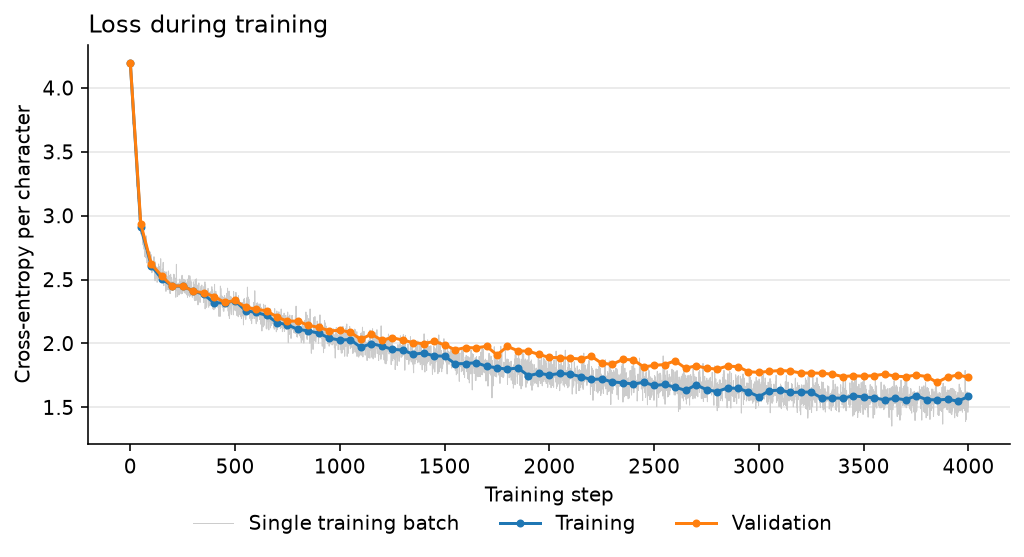

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=144, layout="constrained")
ax.plot(batch_loss, color="0.8", linewidth=0.5, label="Single training batch")
ax.plot(eval_steps, train_loss, marker="o", markersize=3, label="Training")
ax.plot(eval_steps, val_loss, marker="o", markersize=3, label="Validation")
ax.set(xlabel="Training step", ylabel="Cross-entropy per character")
ax.set_title("Loss during training", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(labels),
    frameon=False,
)
plt.show()

## Sampling

Text comes out one character at a time. The model reads the last `block_size` characters generated so
far, the logits at the final position are divided by a temperature, and the next character is drawn from
their softmax. A temperature below 1 sharpens the distribution toward likely characters, and 0.8 is the
value nanoGPT's sampling script uses. Generation starts from a single newline, as in nanoGPT.

The layers are reusable: applying `forward` to a new symbolic input builds a new graph that reads the
same shared weights training just updated. The sampling step applies it to the current context window,
and `pytensor.scan` repeats the step, carrying the generated characters and the random generator from
one step to the next. The whole loop compiles to a single function.

In [12]:
def sample_step(position, ids, rng, temperature):
    context = ids[pt.maximum(position - block_size, 0) : position]
    probabilities = pt.special.softmax(forward(context[None, :])[0, -1] / temperature)
    next_rng, next_id = ptr.categorical(p=probabilities, rng=rng, return_next_rng=True)
    return pt.set_subtensor(ids[position], next_id), next_rng


prompt = pt.vector("prompt", dtype="int64")
n_new = pt.scalar("n_new", dtype="int64")
temperature = pt.scalar("temperature", dtype=floatX)
sample_rng = pytensor.shared(np.random.default_rng(sum(map(ord, "sampling"))))

generated_ids = pt.concatenate([prompt, pt.zeros((n_new,), dtype="int64")])
positions = pt.arange(prompt.shape[0], prompt.shape[0] + n_new)
id_history, final_rng = pytensor.scan(
    sample_step,
    sequences=[positions],
    outputs_info=[generated_ids, sample_rng],
    non_sequences=[temperature],
    return_updates=False,
)

sample = pytensor.function(
    inputs=[prompt, n_new, temperature],
    outputs=id_history[-1],
    updates={sample_rng: final_rng},
)

In [13]:
print(decode(sample(prompt=encode("\n"), n_new=500, temperature=0.8)))



ROMEO:
There may to of good of me: toward I am no the bear
And what and day our bornesty lie here the thous
He is depossion blood'd preclous to him.

BUCKINGHAM:
What shout you say approIne.

KING EDWARD IV:
O much:
So women a lout the atters in shall that he
wos any not wrongs, and so took my hold,
I the duke see mind my but my have tongue.

COMINIUS:
O of Marwick's is thy chrathes of the charnely the
promping reaths: dlead I have for of thing
Starrignes, secle; the green in herMastio
Intend h


## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 7, 2026

## Watermark

In [14]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sat, 07 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

matplotlib : 3.11.2
numpy      : 2.5.4
pytensor   : 3.3.8
pytensor_ml: 0.4.0
tqdm       : 4.70.1

Watermark: 2.6.0



# Thumbnail Image

The cell below draws this notebook's card image for the docs gallery. Its `gallery-thumbnail` tag selects
it as the thumbnail, and its `remove-cell` tag, shared with this heading, keeps both off the rendered page.

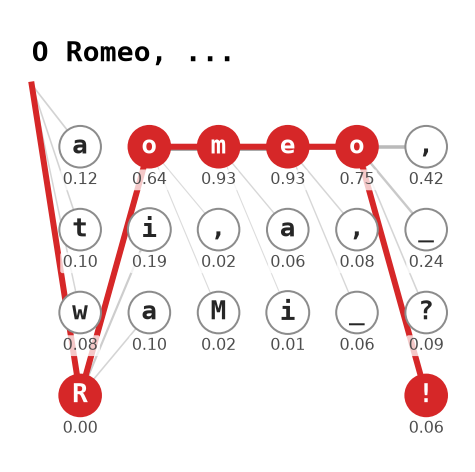

In [15]:
seed = "O Romeo, "
true_continuation = "Romeo!"
top_k = 3

context = pt.vector("context", dtype="int64")
next_character_probabilities = pytensor.function(
    inputs=[context],
    outputs=pt.special.softmax(forward(context[None, :])[0, -1]),
)


def predict(prefix):
    return next_character_probabilities(encode(prefix)[-block_size:])


def readable(character):
    return {" ": "_", "\n": "\\n"}.get(character, character)


# Every column is predicted from the true prefix, so it shows what the model expected at that point of
# the real line. The true character takes its rank among the top_k, or the row below them.
columns = []
for step, true_character in enumerate(true_continuation):
    probabilities = predict(seed + true_continuation[:step])
    top = list(np.argsort(probabilities)[::-1][:top_k])
    true_index = char_to_id[true_character]
    rows = top if true_index in top else [*top, true_index]
    columns.append([(characters[index], probabilities[index]) for index in rows])

true_rows = [
    [character for character, _ in column].index(true_character)
    for column, true_character in zip(columns, true_continuation, strict=True)
]

# The seed sits above the first column, and its edges fan out from an anchor just below the text.
anchor = (-0.7, 0.75)
true_points = [anchor] + [(step, -row) for step, row in enumerate(true_rows)]

fig, ax = plt.subplots(figsize=(4, 4), dpi=144)
ax.set_axis_off()

for step, column in enumerate(columns):
    parent = true_points[step]
    for row, (_, probability) in enumerate(column):
        ax.plot(
            [parent[0], step],
            [parent[1], -row],
            color="0.55",
            linewidth=0.5 + 3 * probability,
            alpha=0.3 + 0.7 * probability,
            zorder=1,
        )

ax.plot(*zip(*true_points, strict=True), color="C3", linewidth=3, zorder=2)

for step, column in enumerate(columns):
    for row, (character, probability) in enumerate(column):
        is_true = row == true_rows[step]
        ax.text(
            step,
            -row,
            readable(character),
            color="white" if is_true else "0.15",
            fontfamily="monospace",
            fontsize=13,
            fontweight="bold",
            ha="center",
            va="center",
            zorder=3,
            bbox={
                "boxstyle": "circle,pad=0.3",
                "facecolor": "C3" if is_true else "white",
                "edgecolor": "C3" if is_true else "0.55",
            },
        )
        ax.text(
            step,
            -row - 0.45,
            f"{probability:.2f}",
            fontsize=8,
            color="0.3",
            ha="center",
            zorder=3,
            bbox={
                "boxstyle": "round,pad=0.15",
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.75,
            },
        )

ax.text(
    anchor[0],
    anchor[1] + 0.2,
    "O Romeo, ...",
    fontfamily="monospace",
    fontsize=14,
    fontweight="bold",
    ha="left",
    va="bottom",
)
ax.set(xlim=(-0.95, len(true_continuation) - 0.5), ylim=(-top_k - 0.75, 1.6))
plt.show()